In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import ast

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [43]:
# Load the cleaned job dataset
jobs = pd.read_csv("../data/processed/jobs_cleaned.csv")

# Load the new synthetic user interactions (4,000 users)
interactions = pd.read_csv(
    "../data/processed/user_interactions_v2.csv"
)

print("Datasets loaded successfully!")

print("Jobs:", jobs.shape)
print("Interactions:", interactions.shape)

print("Unique users:", interactions['user_id'].nunique())
print("Unique jobs:", interactions['job_id'].nunique())

interactions.head()

Datasets loaded successfully!
Jobs: (1020, 13)
Interactions: (80224, 6)
Unique users: 4000
Unique jobs: 1020


,user_id,job_id,interaction_type,rating,relevance_score,is_relevant
0,USER_001,58,save,3,0.517857,1
1,USER_001,579,save,3,0.465179,1
2,USER_001,214,view,1,0.536607,1
3,USER_001,852,apply,5,0.465179,1
4,USER_001,276,view,1,0.552679,1


*Create the bipartite graph*

In [44]:
# Initialize an undirected graph
job_graph = nx.Graph()

# Add user nodes
users = interactions['user_id'].unique()

for user in users:
    job_graph.add_node(
        user,
        node_type='user'
    )

# Add job nodes
for _, job in jobs.iterrows():
    job_graph.add_node(
        f"JOB_{job['id']}",
        node_type='job',
        title=job['title'],
        company=job['company']
    )

# Add edges between users and jobs
for _, interaction in interactions.iterrows():

    user_id = interaction['user_id']
    job_id = f"JOB_{interaction['job_id']}"

    job_graph.add_edge(
        user_id,
        job_id,
        interaction_type=interaction['interaction_type'],
        rating=interaction['rating'],
        weight=interaction['rating']
    )

print("Bipartite graph created successfully!")

Bipartite graph created successfully!


Creates a node for every user.

Creates a node for every job.

Connects each user to jobs they interacted with.

Stores the interaction type and rating on each edge.

In [45]:
#Examine the graph structure
print("Number of nodes:", job_graph.number_of_nodes())
print("Number of edges:", job_graph.number_of_edges())

# Count user and job nodes
user_nodes = [
    node for node, data in job_graph.nodes(data=True)
    if data['node_type'] == 'user'
]

job_nodes = [
    node for node, data in job_graph.nodes(data=True)
    if data['node_type'] == 'job'
]

print("Number of user nodes:", len(user_nodes))
print("Number of job nodes:", len(job_nodes))

Number of nodes: 5020
Number of edges: 80224
Number of user nodes: 4000
Number of job nodes: 1020


**Visualize the bipartite graph** *Using 10 users*

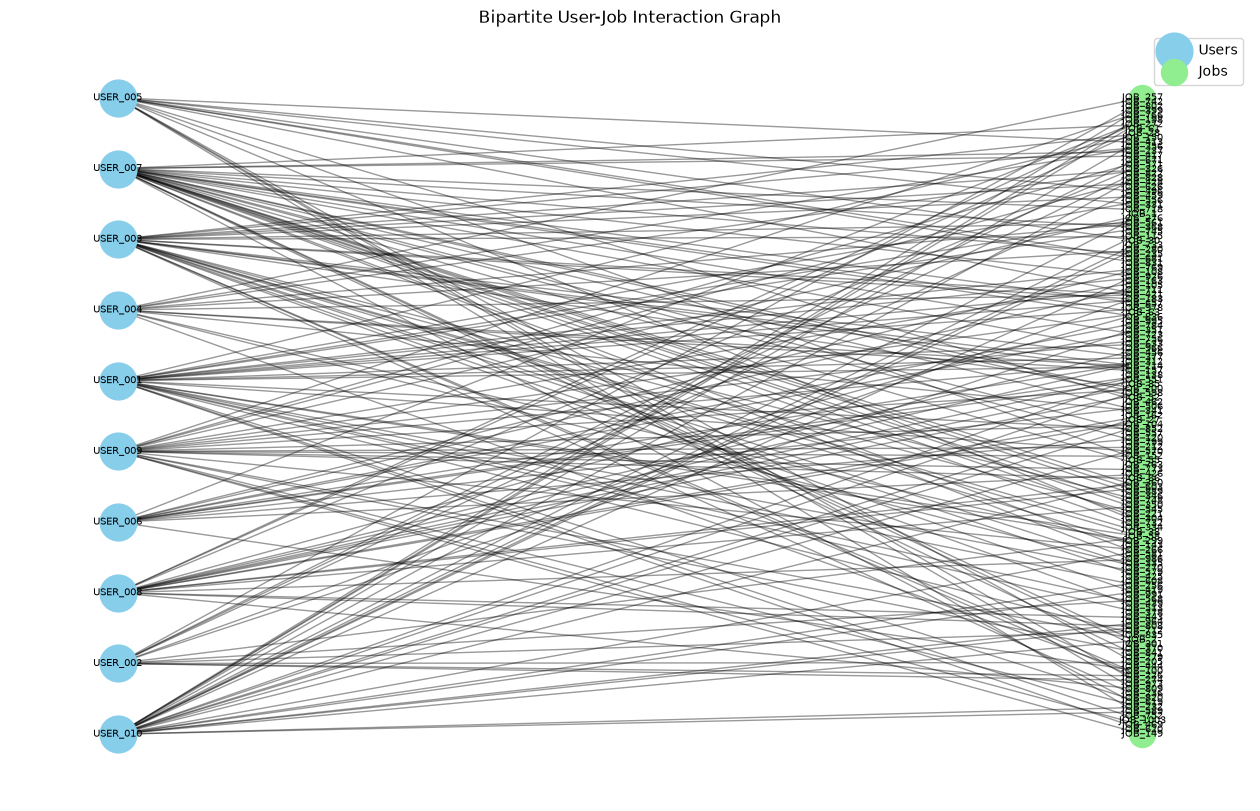

In [46]:
# Select 10 sample users
sample_users = user_nodes[:10]

# Get all jobs connected to these users
sample_jobs = set()

for user in sample_users:
    sample_jobs.update(job_graph.neighbors(user))

# Create a smaller graph for visualization
sample_graph = job_graph.subgraph(
    sample_users + list(sample_jobs)
).copy()

# Separate user and job nodes
sample_user_nodes = [
    node for node, data in sample_graph.nodes(data=True)
    if data['node_type'] == 'user'
]

sample_job_nodes = [
    node for node, data in sample_graph.nodes(data=True)
    if data['node_type'] == 'job'
]

# Create bipartite layout
pos = nx.bipartite_layout(
    sample_graph,
    sample_user_nodes
)

# Draw graph
plt.figure(figsize=(16, 10))

nx.draw_networkx_nodes(
    sample_graph,
    pos,
    nodelist=sample_user_nodes,
    node_color='skyblue',
    node_size=700,
    label='Users'
)

nx.draw_networkx_nodes(
    sample_graph,
    pos,
    nodelist=sample_job_nodes,
    node_color='lightgreen',
    node_size=350,
    label='Jobs'
)

nx.draw_networkx_edges(
    sample_graph,
    pos,
    alpha=0.4,
    width=1
)

nx.draw_networkx_labels(
    sample_graph,
    pos,
    font_size=7
)

plt.title('Bipartite User-Job Interaction Graph')
plt.legend()
plt.axis('off')
plt.show()

*Analyse job popularity*

In [47]:
# Calculate the degree of each job node
job_degrees = {
    node: job_graph.degree(node)
    for node in job_nodes
}

# Convert results into a DataFrame
job_popularity = pd.DataFrame(
    job_degrees.items(),
    columns=['job_node', 'interaction_count']
)

# Sort by number of interactions
job_popularity = job_popularity.sort_values(
    by='interaction_count',
    ascending=False
)

# Extract the original job ID
job_popularity['job_id'] = (
    job_popularity['job_node'].str.replace('JOB_', '', regex=False)
    .astype(int)
)

# Add job information
job_popularity = job_popularity.merge(
    jobs[['id', 'title', 'company']],
    left_on='job_id',
    right_on='id',
    how='left'
)

job_popularity[
    ['job_id', 'title', 'company', 'interaction_count']
].head(10)

,job_id,title,company,interaction_count
0,346,Software Engineer Full Stack & Application Development I (Full Time) – United States,Cisco,972
1,312,AI/ML Research Intern - PHD Level - Remote,Optum,937
2,926,Software Engineer Full Stack & Application Development I (Full Time) – United States,Cisco,936
3,378,Software Engineer Full Stack & Application Development I (Full Time) – United States,Cisco,934
4,368,Software Engineer Full Stack & Application Development I (Full Time) – United States,Cisco,933
5,66,Agentic AI Engineering Intern,Leidos,875
6,421,Software Developer Internship,HP,857
7,143,2026 Dark Wolf Summer Internship,Dark Wolf,840
8,30,Staff Machine Learning Engineer – Generative AI (Remote),The Home Depot,823
9,63,Machine Learning Engineer,RADAR,819


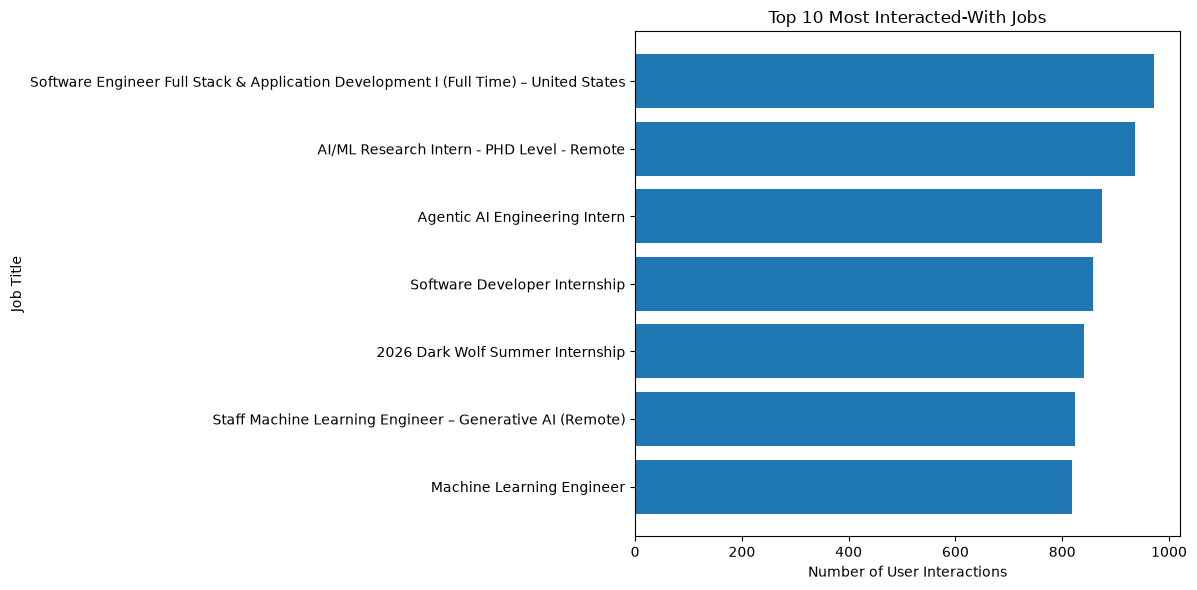

In [48]:
top_10_jobs = job_popularity.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_jobs['title'],
    top_10_jobs['interaction_count']
)

plt.xlabel('Number of User Interactions')
plt.ylabel('Job Title')
plt.title('Top 10 Most Interacted-With Jobs')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

**Implement graph-based job recommendations**

In [49]:
def recommend_jobs_graph(
    user_id,
    job_graph,
    jobs,
    top_n=5,
    alpha=0.85
):

    # Check whether the user exists
    if user_id not in job_graph:
        return "User not found!"

    # Identify jobs the user has already interacted with
    already_interacted = {
        node for node in job_graph.neighbors(user_id)
        if job_graph.nodes[node]['node_type'] == 'job'
    }

    # Personalization: start PageRank from the selected user
    personalization = {
        node: 0 for node in job_graph.nodes()
    }

    personalization[user_id] = 1

    # Calculate Personalized PageRank
    pagerank_scores = nx.pagerank(
        job_graph,
        alpha=alpha,
        personalization=personalization,
        weight='weight'
    )

    # Collect candidate jobs
    recommendations = []

    for node, score in pagerank_scores.items():

        if job_graph.nodes[node]['node_type'] != 'job':
            continue

        if node in already_interacted:
            continue

        recommendations.append({
            'job_id': int(node.replace('JOB_', '')),
            'graph_score': score
        })

    # Convert recommendations into a DataFrame
    recommendations = pd.DataFrame(recommendations)

    if recommendations.empty:
        return "No recommendations available!"

    # Sort by PageRank score
    recommendations = recommendations.sort_values(
        by='graph_score',
        ascending=False
    ).head(top_n)

    # Add job information
    recommendations = recommendations.merge(
        jobs[['id', 'title', 'company', 'location', 'employment_type']],
        left_on='job_id',
        right_on='id',
        how='left'
    )

    return recommendations[
        [
            'job_id',
            'title',
            'company',
            'location',
            'employment_type',
            'graph_score'
        ]
    ]

In [50]:
test_user = 'USER_001'

graph_recommendations = recommend_jobs_graph(
    user_id=test_user,
    job_graph=job_graph,
    jobs=jobs,
    top_n=5
)

graph_recommendations

,job_id,title,company,location,employment_type,graph_score
0,346,Software Engineer Full Stack & Application Development I (Full Time) – United States,Cisco,"Dallas, TX",Full-time,0.006407
1,143,2026 Dark Wolf Summer Internship,Dark Wolf,"Herndon, VA",Internship,0.005486
2,411,Software Engineer Sr - Cloud Engineer,PNC,"Farmers Branch, TX",Full-time,0.005441
3,237,Software Developer Co-Op Fall 2026,IBM,"Durham, NC",Internship,0.004522
4,282,"Software Engineer, Ground Software",Muon Space,"San Jose, CA",Full-time,0.004387


In [51]:
# Verify that previously interacted jobs are excluded
if isinstance(graph_recommendations, pd.DataFrame):

    previously_interacted = {
        node.replace('JOB_', '')
        for node in job_graph.neighbors(test_user)
    }

    recommended_job_ids = set(
        graph_recommendations['job_id'].astype(str)
    )

    print(
        "Previously interacted jobs recommended:",
        len(previously_interacted.intersection(recommended_job_ids))
    )

Previously interacted jobs recommended: 0


In [52]:
import os
import pickle

os.makedirs("../models", exist_ok=True)

with open("../models/job_graph.pkl", "wb") as file:
    pickle.dump(job_graph, file)

print("Graph model saved successfully!")

Graph model saved successfully!
